<a href="https://colab.research.google.com/github/fabianmoore/MineriaDatos/blob/main/IEI097_Lab2_12_MLP_MLflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IEI097 – Lab 2.12: MLP + MLflow (Breast Cancer Wisconsin)
**Nombre:** Fabián Moore  
**SEED:** 205474323  
**Fecha:** 10-11-2026

## Paso 1 – Entorno y semilla personal
**Por qué:** la semilla personal (SEED = 205474323) hace que tus resultados sean repetibles y distintos a los de tus compañeros. Las versiones de las librerías forman parte del experimento.

In [1]:
!pip install -q mlflow pyngrok

In [2]:
import random, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, mlflow

SEED = 205474323
random.seed(SEED)
np.random.seed(SEED)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("mlflow:", mlflow.__version__)

pandas: 2.2.3
scikit-learn: 1.6.1
mlflow: 3.18.0


## Paso 2 – Carga y preparación de datos
**Por qué:** `Unnamed: 32` está vacía (residuo del archivo) e `id` es solo un identificador; ninguna describe al tumor, así que se eliminan. M se codifica como 1 porque es la clase de interés (maligno).

In [4]:
import kagglehub
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ruta = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(ruta))   # confirmar cuál es el CSV principal

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']


In [5]:
df = pd.read_csv(os.path.join(ruta, "data.csv"))
print(df.shape)
df.info()

(569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

In [6]:
vacias = df.isna().sum()
print(vacias[vacias > 0])   # debería aparecer solo Unnamed: 32

Unnamed: 32    569
dtype: int64


In [7]:
df = df.drop(columns=["Unnamed: 32", "id"])
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print(df["diagnosis"].value_counts())
print(df["diagnosis"].value_counts(normalize=True).round(3))

diagnosis
0    357
1    212
Name: count, dtype: int64
diagnosis
0    0.627
1    0.373
Name: proportion, dtype: float64


Balance de clases: benignos = 357 (62,7 %), malignos = 212 (37,3 %), total 569. Hay más tumores benignos que malignos.

In [8]:
cols = ["radius_mean", "area_mean", "smoothness_mean"]
rangos = pd.DataFrame({"min": df[cols].min(), "max": df[cols].max()})
rangos["rango"] = rangos["max"] - rangos["min"]
print(rangos)
print("area_mean / radius_mean (veces):", round(rangos.loc["area_mean","rango"] / rangos.loc["radius_mean","rango"], 1))
print("area_mean / smoothness_mean (veces):", round(rangos.loc["area_mean","rango"] / rangos.loc["smoothness_mean","rango"], 1))

                       min        max       rango
radius_mean        6.98100    28.1100    21.12900
area_mean        143.50000  2501.0000  2357.50000
smoothness_mean    0.05263     0.1634     0.11077
area_mean / radius_mean (veces): 111.6
area_mean / smoothness_mean (veces): 21282.8


Evidencia de escala: El rango de "area_mean" (2357,5) es unas 111,6 veces el de "radius_mean" (21,13) y unas 21.283 veces el de "smoothness_mean" (0,11). Con diferencias de magnitud tan grandes, "area_mean" dominaría la suma de las neuronas del MLP si no se escalan las variables. Por eso es esperable que el escalado mejore el entrenamiento.

## Paso 3 – Partición estratificada
 "Stratify=y" mantiene la proporción de malignos en train y test. Se deja la partición fija para que cualquier diferencia entre runs venga solo del cambio que introduzcas.

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("train:", X_train.shape, "test:", X_test.shape)
print("proporción maligno train:", round(y_train.mean(), 3))
print("proporción maligno test :", round(y_test.mean(), 3))

train: (455, 30) test: (114, 30)
proporción maligno train: 0.374
proporción maligno test : 0.368


## Paso 4 – MLflow en Colab
El servidor guarda los runs en SQLite y ngrok lo publica en una URL temporal para abrir la interfaz en tu navegador.  

In [11]:
import subprocess, time, requests
from pyngrok import ngrok

def servidor_listo():
    try:
        return requests.get("http://127.0.0.1:5000/health", timeout=3).ok
    except requests.RequestException:
        return False

# Lanzar el servidor solo si todavía no está corriendo
if not servidor_listo():
    env = dict(os.environ,
               MLFLOW_SERVER_ALLOWED_HOSTS="*",
               MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*")
    subprocess.Popen(["mlflow", "server",
                      "--backend-store-uri", "sqlite:///mlflow.db",
                      "--host", "127.0.0.1", "--port", "5000"], env=env)

# Esperar hasta 2 minutos a que responda
for _ in range(120):
    if servidor_listo():
        break
    time.sleep(1)
else:
    raise RuntimeError("El servidor MLflow no respondió en 2 minutos")

ngrok.set_auth_token(userdata.get("NGROK_AUTHTOKEN"))
ngrok.kill()
tunel = ngrok.connect(5000)
print("MLflow UI:", tunel.public_url)

MLflow UI: https://disrupt-protozoan-deny.ngrok-free.dev


In [12]:
APELLIDO = "Moore"
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment(f"IEI097-L2.12-{APELLIDO}")

2026/11/11 00:53:07 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-L2.12-Moore' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794358387044, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794358387044, lifecycle_stage='active', name='IEI097-L2.12-Moore', tags={}, trace_location=None, workspace='default'>

## Paso 5 – Experimentos controlados
Runs A y B – ¿el escalado mejorará, empeorará o no cambiará el resultado?  
**Hipótesis:** creo que el escalado va a mejorar el resultado, o al menos la convergencia. Variables como "area_mean" tienen un rango mucho mayor que "smoothness_mean", y en un MLP las variables de magnitud grande dominan la suma de las neuronas, pueden saturar las activaciones y hacen el descenso del gradiente lento o inestable. Con "StandardScaler" todas las variables quedan con media 0 y desviación 1, por lo que espero mejor exactitud, mejor sensibilidad y menos iteraciones en el run B que en el A.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")   # avisos de convergencia en el run sin escalar

def correr_experimento(nombre, escalar, capas, activacion, seed_modelo,
                       fase="experimentos", alpha=0.0001, max_iter=500):
    # El escalado va dentro del Pipeline: se ajusta solo con train (sin fuga de datos)
    pasos = []
    if escalar:
        pasos.append(("scaler", StandardScaler()))
    pasos.append(("mlp", MLPClassifier(hidden_layer_sizes=capas, activation=activacion,
                                       alpha=alpha, max_iter=max_iter,
                                       random_state=seed_modelo)))
    pipe = Pipeline(pasos)

    with mlflow.start_run(run_name=nombre):
        mlflow.set_tag("fase", fase)
        mlflow.log_params({"arquitectura": str(capas), "activacion": activacion,
                           "alpha": alpha, "max_iter": max_iter,
                           "random_state": seed_modelo, "escalado": escalar,
                           "semilla_particion": SEED})

        pipe.fit(X_train, y_train)
        mlp = pipe.named_steps["mlp"]
        pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)

        mlflow.log_metrics({
            "acc_train": accuracy_score(y_train, pred_tr),
            "acc_test": accuracy_score(y_test, pred_te),
            "recall_maligno": recall_score(y_test, pred_te, pos_label=1),
            "f1": f1_score(y_test, pred_te, pos_label=1),
            "n_iter": mlp.n_iter_})

        for epoca, perdida in enumerate(mlp.loss_curve_):
            mlflow.log_metric("train_loss", perdida, step=epoca)

        ConfusionMatrixDisplay.from_predictions(
            y_test, pred_te, display_labels=["benigno", "maligno"])
        plt.title(nombre)
        mlflow.log_figure(plt.gcf(), "matriz_confusion.png")
        plt.show()

    return {"run": nombre, "acc_train": accuracy_score(y_train, pred_tr),
            "acc_test": accuracy_score(y_test, pred_te),
            "recall": recall_score(y_test, pred_te, pos_label=1),
            "n_iter": mlp.n_iter_}

**Por qué `max_iter=500`:** con el valor por defecto (200) el MLP sin escalar suele cortar antes de converger; así todos los runs tienen el mismo margen. Es igual en todos, por lo que no rompe el "un cambio a la vez".

### Run A – sin escalado, (30,), relu (punto de partida)

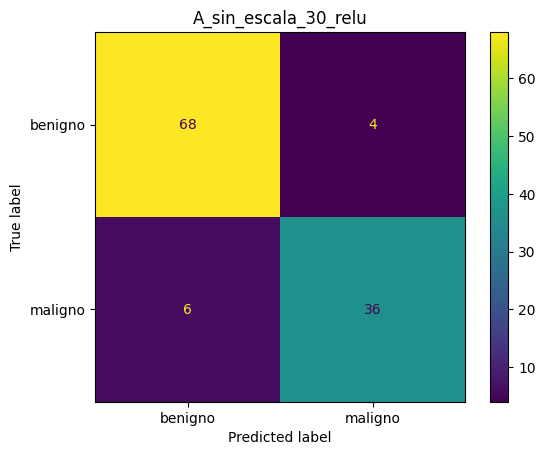

🏃 View run A_sin_escala_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/707eb1fa477d4a6798745e9364c623d6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


{'run': 'A_sin_escala_30_relu',
 'acc_train': 0.9472527472527472,
 'acc_test': 0.9122807017543859,
 'recall': 0.8571428571428571,
 'n_iter': 353}

In [14]:
resA = correr_experimento("A_sin_escala_30_relu", False, (30,), "relu", SEED); resA

**Interpretación A:** punto de partida sin escalado. Las variables con magnitudes grandes (como area_mean) dominan el entrenamiento, por lo que este run sirve de referencia para medir el efecto del escalado.

### Run B – con escalado (cambia solo el escalado)

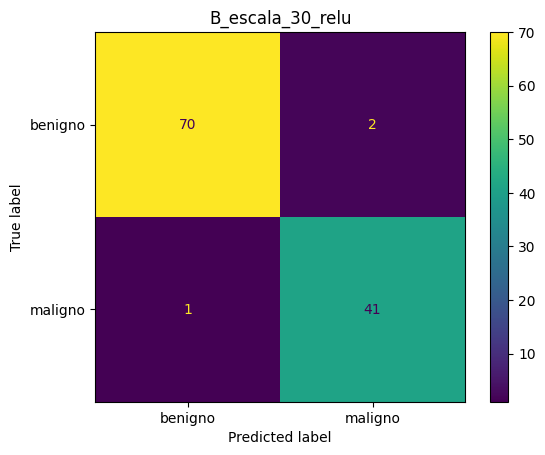

🏃 View run B_escala_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/fc6dade4ed7142219921e41a0ec42308
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


{'run': 'B_escala_30_relu',
 'acc_train': 0.9912087912087912,
 'acc_test': 0.9736842105263158,
 'recall': 0.9761904761904762,
 'n_iter': 337}

In [15]:
resB = correr_experimento("B_escala_30_relu", True, (30,), "relu", SEED); resB

**Interpretación B:** al agregar solo el escalado, la exactitud subió de 0.912 a 0.974 y la sensibilidad de 0.857 a 0.976 (los falsos negativos bajaron de 6 a 1). Esto confirma mi hipótesis en cuanto al desempeño. Las iteraciones casi no cambiaron (353 en A y 337 en B), así que no se cumplió que convergiera mucho más rápido.

### Run C – arquitectura (64, 32)

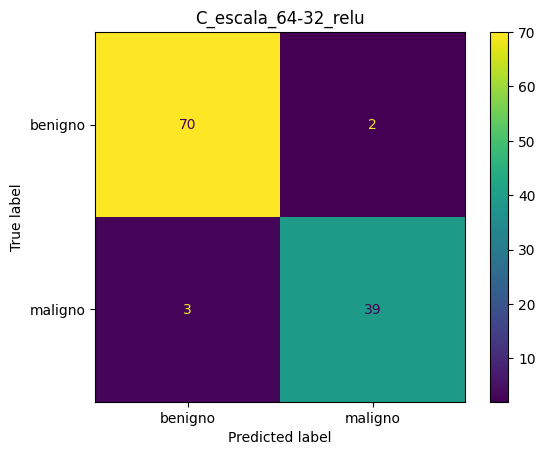

🏃 View run C_escala_64-32_relu at: http://127.0.0.1:5000/#/experiments/1/runs/bc57a249e4ce42d3aa5bb0b1d5746872
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


{'run': 'C_escala_64-32_relu',
 'acc_train': 1.0,
 'acc_test': 0.956140350877193,
 'recall': 0.9285714285714286,
 'n_iter': 196}

In [16]:
resC = correr_experimento("C_escala_64-32_relu", True, (64, 32), "relu", SEED); resC

**Interpretación C:** Con (64, 32) el resultado fue algo peor que B: exactitud 0.956 y sensibilidad 0.929, con exactitud de entrenamiento 1.0, es decir, memoriza el train. La red más grande no aportó mejora en este dataset pequeño. La diferencia es de pocas muestras de prueba, y se compara con la variación entre semillas del Paso 6.

### Run D – activación tanh (cambia solo la activación)

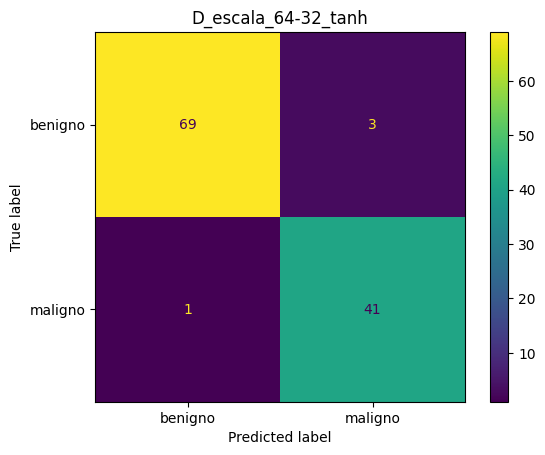

🏃 View run D_escala_64-32_tanh at: http://127.0.0.1:5000/#/experiments/1/runs/6391670dfb6842859e04c918fcd85dd0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


{'run': 'D_escala_64-32_tanh',
 'acc_train': 1.0,
 'acc_test': 0.9649122807017544,
 'recall': 0.9761904761904762,
 'n_iter': 330}

In [17]:
resD = correr_experimento("D_escala_64-32_tanh", True, (64, 32), "tanh", SEED); resD

**Interpretación D:** tanh da un resultado similar a relu con esta arquitectura, ya que con datos escalados ambas activaciones funcionan bien. Cualquier diferencia pequeña puede deberse al azar.

## Paso 6 – Semilla y replicación
**Por qué:** un solo resultado depende de la semilla elegida. Repetir la configuración C con 5 semillas del modelo (partición fija) mide cuánto varía por azar. La réplica con la misma semilla debe dar números idénticos.

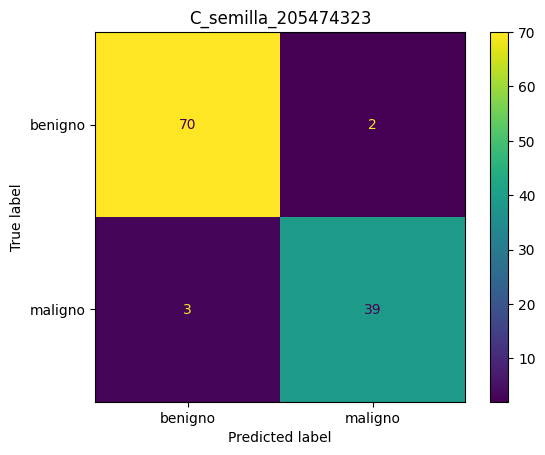

🏃 View run C_semilla_205474323 at: http://127.0.0.1:5000/#/experiments/1/runs/d416ec65b12140debab15e91a3e41390
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


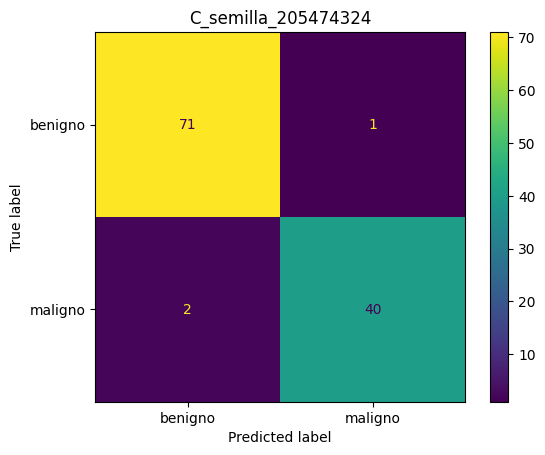

🏃 View run C_semilla_205474324 at: http://127.0.0.1:5000/#/experiments/1/runs/68205dc9f30b44008a213952e953d999
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


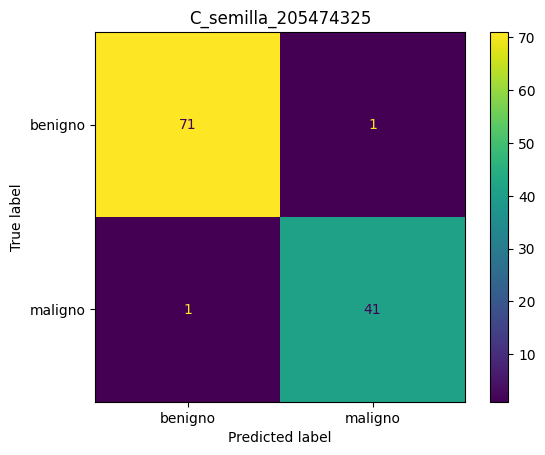

🏃 View run C_semilla_205474325 at: http://127.0.0.1:5000/#/experiments/1/runs/c87cb24d15f74650adcb71388c83d568
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


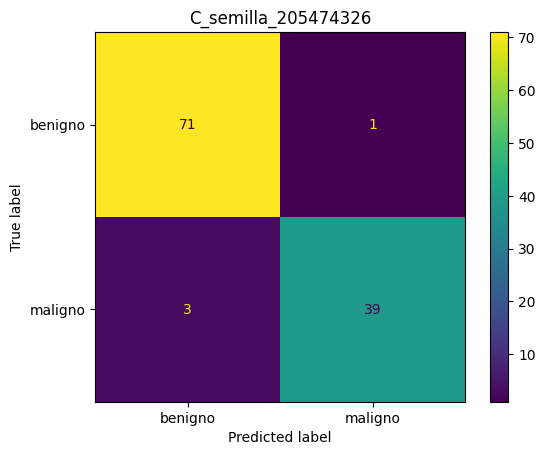

🏃 View run C_semilla_205474326 at: http://127.0.0.1:5000/#/experiments/1/runs/47fc02b4118c4bf095e5049e34790128
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


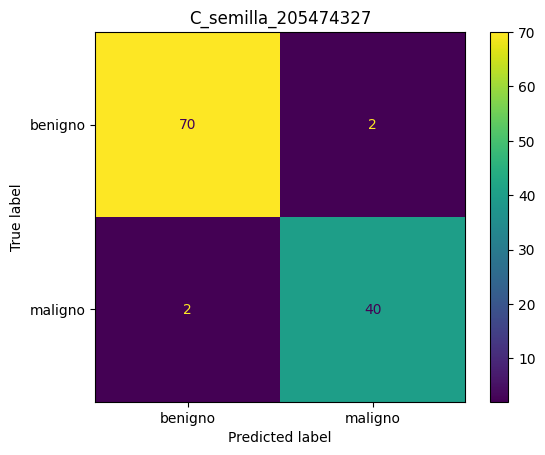

🏃 View run C_semilla_205474327 at: http://127.0.0.1:5000/#/experiments/1/runs/298c1667da674b95935b25498cd44757
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,run,acc_train,acc_test,recall,n_iter
0,C_semilla_205474323,1.0,0.956140,0.928571,196
1,C_semilla_205474324,1.0,0.973684,0.952381,220
2,C_semilla_205474325,1.0,0.982456,0.976190,213
3,C_semilla_205474326,1.0,0.964912,0.928571,200
4,C_semilla_205474327,1.0,0.964912,0.952381,194


In [19]:
filas = []
for s in range(SEED, SEED + 5):
    r = correr_experimento(f"C_semilla_{s}", True, (64, 32), "relu", s, fase="semillas")
    filas.append(r)
semillas_df = pd.DataFrame(filas)
semillas_df

In [20]:
resumen = pd.DataFrame({
    "min": semillas_df[["acc_test", "recall"]].min(),
    "max": semillas_df[["acc_test", "recall"]].max()})
resumen["rango"] = resumen["max"] - resumen["min"]
resumen

,min,max,rango
acc_test,0.956140,0.982456,0.026316
recall,0.928571,0.976190,0.047619


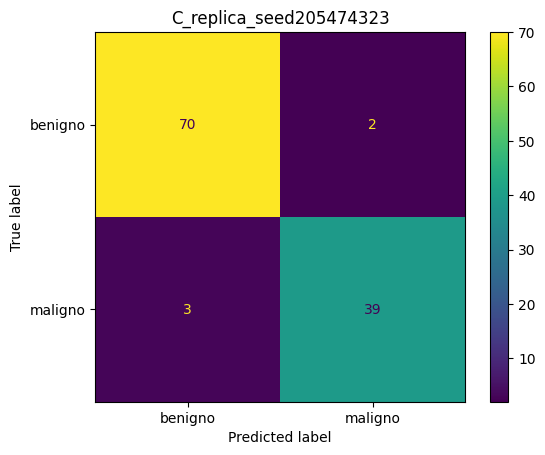

🏃 View run C_replica_seed205474323 at: http://127.0.0.1:5000/#/experiments/1/runs/bea3d280b6204058a88348982a2774b6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run C   : {'run': 'C_escala_64-32_relu', 'acc_train': 1.0, 'acc_test': 0.956140350877193, 'recall': 0.9285714285714286, 'n_iter': 196}
Réplica : {'run': 'C_replica_seed205474323', 'acc_train': 1.0, 'acc_test': 0.956140350877193, 'recall': 0.9285714285714286, 'n_iter': 196}
Diferencia acc_test: 0.0 | recall: 0.0


In [21]:
rep = correr_experimento(f"C_replica_seed{SEED}", True, (64, 32), "relu", SEED, fase="replica")
print("Run C   :", resC)
print("Réplica :", rep)
print("Diferencia acc_test:", abs(resC["acc_test"] - rep["acc_test"]),
      "| recall:", abs(resC["recall"] - rep["recall"]))

## Paso 7 – Exportar evidencia
**En la interfaz de MLflow (toma capturas con la URL de ngrok visible):**
1. Tabla de runs ordenada por `recall_maligno` (≥ 10 runs).
2. Compare de ≥ 4 runs y gráfico `train_loss` de ≥ 2 runs.
3. Una ejecución con el artefacto `matriz_confusion.png`.
4. Dos runs con misma semilla y métricas idénticas (C y la réplica).

In [22]:
runs = mlflow.search_runs()
print(len(runs), "runs")
cols = ["tags.mlflow.runName", "tags.fase", "params.arquitectura", "params.activacion",
        "params.alpha", "params.escalado", "params.random_state",
        "metrics.acc_train", "metrics.acc_test", "metrics.recall_maligno",
        "metrics.f1", "metrics.n_iter"]
runs[cols].sort_values("metrics.recall_maligno", ascending=False).to_csv("runs.csv", index=False)
runs[cols].sort_values("metrics.recall_maligno", ascending=False)

11 runs


,tags.mlflow.runName,tags.fase,params.arquitectura,params.activacion,params.alpha,params.escalado,params.random_state,metrics.acc_train,metrics.acc_test,metrics.recall_maligno,metrics.f1,metrics.n_iter
9,B_escala_30_relu,experimentos,"(30,)",relu,0.0001,True,205474323,0.991209,0.973684,0.976190,0.964706,337.0
7,D_escala_64-32_tanh,experimentos,"(64, 32)",tanh,0.0001,True,205474323,1.000000,0.964912,0.976190,0.953488,330.0
3,C_semilla_205474325,semillas,"(64, 32)",relu,0.0001,True,205474325,1.000000,0.982456,0.976190,0.976190,213.0
1,C_semilla_205474327,semillas,"(64, 32)",relu,0.0001,True,205474327,1.000000,0.964912,0.952381,0.952381,194.0
4,C_semilla_205474324,semillas,"(64, 32)",relu,0.0001,True,205474324,1.000000,0.973684,0.952381,0.963855,220.0
2,C_semilla_205474326,semillas,"(64, 32)",relu,0.0001,True,205474326,1.000000,0.964912,0.928571,0.951220,200.0
0,C_replica_seed205474323,replica,"(64, 32)",relu,0.0001,True,205474323,1.000000,0.956140,0.928571,0.939759,196.0
6,E_escala_64-32_relu_alpha0.01,experimentos,"(64, 32)",relu,0.01,True,205474323,1.000000,0.956140,0.928571,0.939759,199.0
5,C_semilla_205474323,semillas,"(64, 32)",relu,0.0001,True,205474323,1.000000,0.956140,0.928571,0.939759,196.0
8,C_escala_64-32_relu,experimentos,"(64, 32)",relu,0.0001,True,205474323,1.000000,0.956140,0.928571,0.939759,196.0


In [23]:
from google.colab import files
files.download("runs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Paso 8 – Preguntas de cierre
**1. ¿Qué cambió al escalar las variables?**  
Al pasar de A_sin_escala_30_relu a B_escala_30_relu, la exactitud en prueba subió de 0.912 a 0.974 y la sensibilidad de 0.857 a 0.976. Los falsos negativos bajaron de 6 a 1. Las iteraciones casi no cambiaron (353 y 337). Esto ocurre porque el feature scaling deja las variables en escalas comparables: sin él, variables como area_mean (rango de unas 21.000 veces el de smoothness_mean) dominan la suma de las neuronas y dificultan el descenso del gradiente.

**2. ¿Más capas y neuronas mejoraron el resultado?**  
No. Al comparar B (30,) con C (64, 32), la exactitud bajó de 0.974 a 0.956 y la sensibilidad de 0.976 a 0.929. C llegó a exactitud de entrenamiento 1.0, lo que indica sobreajuste. Además, con las 5 semillas la exactitud varió en un rango de 0.026, mayor que la diferencia entre B y C (0.018). Por eso concluyo que más capas y neuronas no mejoraron el resultado, y un dataset pequeño (569 filas) no lo necesita.

**3. Variación con las 5 semillas**  
Con las 5 semillas, la exactitud en prueba varió entre 0.956 y 0.982 (rango 0.026) y la sensibilidad entre 0.929 y 0.976 (rango 0.048). Esta variación es comparable a las diferencias entre B, C y D, así que esas diferencias no se pueden atribuir con seguridad a la configuración. En cambio, el efecto del escalado (A vs B: +0.061 de exactitud y +0.119 de sensibilidad) es mayor que la variación por azar. Para decir que una configuración es mejor no basta un solo run: hay que repetirlo con varias semillas y verificar que la diferencia supere ese rango.

**4. Falso negativo vs. falso positivo**  
En el diagnóstico de cáncer es más costoso el falso negativo: un tumor maligno clasificado como benigno puede retrasar el tratamiento. Un falso positivo genera exámenes adicionales y ansiedad, pero se corrige al confirmar el diagnóstico. Por eso priorizaría la sensibilidad (recall) de la clase maligna, sin descuidar la exactitud.

**5. ¿Qué da MLflow que no daría print()?**  
MLflow guarda para cada run los parámetros, las métricas, la curva de pérdida por época y la matriz de confusión, y permite ordenar y comparar runs lado a lado. Con print() esa información se pierde al cerrar la celda. Para que otra persona pueda replicar el experimento, además registraría las versiones de las librerías, el código (commit de GitHub) y los datos usados, incluida la partición.

In [ ]:
ngrok.kill()   # cerrar el túnel al terminar